# Explanation: why not just use rasterio?


Differences:
+ Order of assignment:
  + rasterio looks at each shape in turn and then updates all of the cells that the shape appears in.
  + this package looks at each cell in turn and records which shapes appear in it.
+ Which polygons are assigned to a cell:
  + rasterio `all_touched` parameter lets you use either all geometries in the cell, or only those either with their centre in the cell or "that are selected by Bresenham's line algorithm".
  + This package gathers all polygons with any geometry in the cell.
+ Which shape gives its value to the cell:
  + rasterio assigns the data to the cells in the order that the shapes appear. If multiple regions appear in the same cell, the value assigned to the cell is for just the last of those regions. This has the effect of picking one of the regions at random rather than looking at which value is most appropriate for the cell.
  + This package gathers all shapes and the proportions of the total shape area in the cell that each region covers. By default the cell value is from the region that covers the most area, but the proportions allow for different selections.
+ Which cells are included:
  + rasterio with `all_touched` will return valid data in cells containing only a tiny proportion of shapes.
  + This package gathers the proportions of cell area covered split by shape so that mostly-empty cells can be set to invalid data.
+ Which values can be burnt to cell:
  + rasterio.features.rasterize() only works with numerical data (dtype int or float), not region names. Could still do a mapping of name to integer then transform the results back to name.
  + This package allows numerical or string data to be assigned to the grid.

Note: rasterio versions since version 1.4b1 can return the grid as masked arrays.

## Code setup

In [2]:
import os
from dataclasses import dataclass

import numpy as np
import json  # to load dict
import geopandas as gpd  # for shape geometry
import matplotlib.pyplot as plt
import rasterio.transform
import rasterio.features

# Add path to package:
import sys
sys.path.insert(0,'../')
import isopods.convert

In [3]:
@dataclass(frozen=True)
class Paths:
    '''Singleton object for storing paths to data and database.'''

    dir_data: str = '../data'

    lsoa_filename: str = 'lsoa2011_devon.geojson'
    dict_filename: str = 'lsoa2011_devon_1k_grid_dict.json'
    lsoa_grid_data_filename: str = 'lsoa2011_devon_1k_grid_data.csv'
    lsoa_grid_mask_filename: str = 'lsoa2011_devon_1k_grid_mask.csv'

paths = Paths()

## Load data

Original geojson with full geometry:

In [4]:
# Load in shape data.g
# Make sure the GeoDataFrame index is the label for each region.
p = os.path.join(paths.dir_data, paths.lsoa_filename)
gdf = gpd.read_file(p).set_index('LSOA11CD')
gdf['geometry'] = gdf.make_valid()
# Check the coordinate reference system (CRS):
print(f'{gdf.crs.name} EPSG:{gdf.crs.to_epsg()}')

# Assign each region a random integer:
np.random.seed(42)
dict_region_value = dict(zip(gdf.index, np.random.randint(0, 11, len(gdf))))
gdf['value'] = gdf.index.map(dict_region_value)

OSGB36 / British National Grid EPSG:27700


In [5]:
gdf.head(2)

,FID,LSOA11NM,LSOA11NMW,BNG_E,BNG_N,LONG,LAT,GlobalID,area_name,geometry,value
LSOA11CD,,,,,,,,,,,
E01015023,14568,Plymouth 003A,Plymouth 003A,247552,60231,-4.14743,50.42208,6e00dc30-ff9b-4373-a273-8f83ac4f0e43,Plymouth,"POLYGON ((247801.375 60189.402, 247893.675 602...",6
E01015024,14569,Plymouth 004A,Plymouth 004A,246298,60366,-4.16512,50.42297,70bf14eb-d03d-425f-804c-8f8fb0266310,Plymouth,"POLYGON ((246716.109 60750.531, 246946.495 608...",3


Grid dictionary:

In [6]:
p = os.path.join(paths.dir_data, paths.dict_filename)
with open(p, 'r') as f:
    transform_dict = json.load(f)

LSOA label grid from this package methods:

In [7]:
p = os.path.join(paths.dir_data, paths.lsoa_grid_data_filename)
lsoa_grid_data = np.loadtxt(p, dtype=str, delimiter=',')
p = os.path.join(paths.dir_data, paths.lsoa_grid_mask_filename)
lsoa_grid_mask = np.loadtxt(p, dtype=bool, delimiter=',')

arr_lsoa = np.ma.MaskedArray(
    lsoa_grid_data, mask=lsoa_grid_mask, dtype=object)
arr_lsoa_values = isopods.convert.convert_grid_values(
    arr_lsoa, dict_region_value)

## rasterio

In [8]:
rasterio.__version__

'1.5.0'

In [23]:
def make_raster_from_vectors(
        _geometry,
        vals_for_colours,
        height,
        width,
        transform
        ):
    """
    # Burn geometries for left-hand map:

    """
    shapes = ((geom, value) for geom, value in
              zip(_geometry, vals_for_colours))
    burned = rasterio.features.rasterize(
        shapes=shapes,
        out_shape=(height, width),
        fill=np.nan,
        transform=transform,
        all_touched=True,
        dtype=float
    )
    burned = np.flip(burned, axis=0)
    return burned

In [24]:
transform = rasterio.transform.from_origin(
    transform_dict['xmin'],
    transform_dict['ymax'],
    transform_dict['cell_width'],
    transform_dict['cell_height']
)

arr_rasterio = make_raster_from_vectors(
    gdf['geometry'],
    gdf['value'],
    transform_dict['n_rows'],
    transform_dict['n_cols'],
    transform,
)

Check that both grids are the same shape:

In [25]:
print(arr_lsoa.shape, arr_rasterio.shape)

(118, 126) (118, 126)


Compare the values for one row of data:

In [26]:
arr_lsoa_values[42]

masked_array(data=[--, --, --, --, --, --, --, --, --, --, --, --, --, --,
                   --, --, --, --, --, --, --, --, --, --, --, --, 4, 4,
                   4, 1, 1, 1, 1, 1, 1, 10, 10, 10, 10, 10, 10, 10, 10, 1,
                   1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 6, 6, 6, 6, 6, 6, 6,
                   5, 5, 5, 5, 5, 5, 5, 3, 3, 3, 3, 3, 3, 2, 2, 10, 10,
                   10, 7, 7, 7, 7, 10, --, --, --, --, --, --, --, --, --,
                   --, --, --, --, --, --, --, --, --, --, --, --, --, --,
                   --, --, --, --, --, --, --, --, --, --, --, --, --, --,
                   --, --, --, --],
             mask=[ True,  True,  True,  True,  True,  True,  True,  True,
                    True,  True,  True,  True,  True,  True,  True,  True,
                    True,  True,  True,  True,  True,  True,  True,  True,
                    True,  True, False, False, False, False, False, False,
                   False, False, False, False, False, False, False, Fal

In [27]:
arr_rasterio[42]

array([nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
        4.,  4.,  1.,  1.,  1.,  1.,  1.,  1.,  1., 10., 10., 10., 10.,
       10., 10.,  0.,  0.,  0.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,
        1.,  1.,  1.,  1.,  6.,  6.,  6.,  6.,  6.,  6.,  6.,  5.,  5.,
        5.,  5.,  5.,  5.,  5.,  5.,  3.,  3.,  3.,  3.,  3.,  2.,  2.,
       10.,  2.,  2.,  7.,  7.,  7.,  7., nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, nan, nan])

The rasterio data type is float. Check that all valid cells contain integer values:

In [28]:
mask = ~np.isnan(arr_rasterio)
print((arr_rasterio[mask] == arr_rasterio[mask].astype(int)).all())

True


## Plot grids

Setup for the plots:

In [29]:
# For plotting the grid with imshow:
extent = (transform_dict['xmin'], transform_dict['xmax'],
          transform_dict['ymin'], transform_dict['ymax'])

# Axis limits for the Exe Estuary:
xlim_exe = (285000, 310000)
ylim_exe = (75000, 100000)

Function to plot shapes on one axis and the grid on another:

In [30]:
def plot_shapes_vs_raster(
        gdf: gpd.GeoDataFrame,
        arr: np.array,
        extent,#: 'list | tuple',
        title: str = '',
        xlim=(None,None),#: 'list | tuple' = (None, None),
        ylim=(None,None),#: 'list | tuple' = (None, None)
    ):
    gk = {'width_ratios': [20, 20, 1], 'wspace': 0.0}
    fig, axs = plt.subplots(1, 3, figsize=(14, 6), gridspec_kw=gk)

    # Draw filled shapes:
    gdf.plot(ax=axs[0], column='value', cmap='plasma')
    
    # Draw gridded data:
    cmap = plt.get_cmap('plasma')
    cl = axs[1].imshow(arr, origin='lower', extent=extent,
                       interpolation='None', cmap=cmap)
    # Only draw colourbar once - expect same for both ax.
    plt.colorbar(cl, cax=axs[-1])
    # Overlay original shapes:
    gdf.plot(ax=axs[1], facecolor='None', edgecolor='k')

    for i in range(2):
        axs[i].set_xlim(xlim)
        axs[i].set_ylim(ylim)
    axs[1].set_yticks([])  # stop clash with other axis
    axs[0].set_title('Original shapes')
    axs[1].set_title(title)
    plt.show()

Run function on the rasterio output and on the grid from this package:

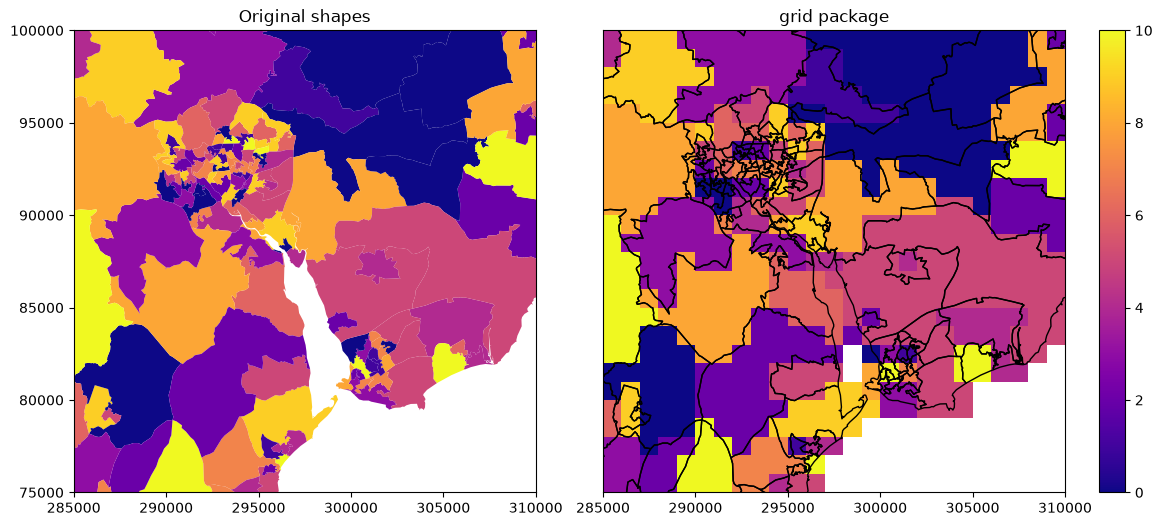

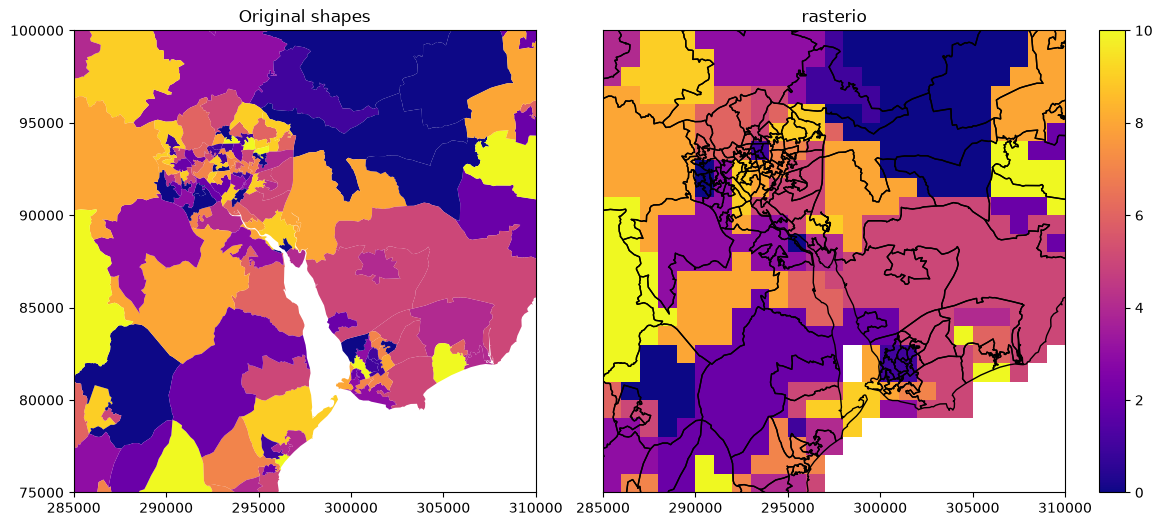

In [31]:
plot_shapes_vs_raster(gdf, arr_lsoa_values, extent,
                      xlim=xlim_exe, ylim=ylim_exe, title='grid package')
plot_shapes_vs_raster(gdf, arr_rasterio, extent,
                      xlim=xlim_exe, ylim=ylim_exe, title='rasterio')